In [1]:
print("Oasis Infobyte - Retail Sales EDA")

Oasis Infobyte - Retail Sales EDA


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
import pandas as pd

file_path = r"C:\Users\Dell\OneDrive\Desktop\retail_sales_dataset.csv"
df = pd.read_csv(file_path)

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [7]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape:
(1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [8]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [9]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [10]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date column converted successfully!")
print(df["Date"].dtype)

Date column converted successfully!
datetime64[us]


In [11]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Total Amount"].sum()

monthly_sales

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Name: Total Amount, dtype: int64

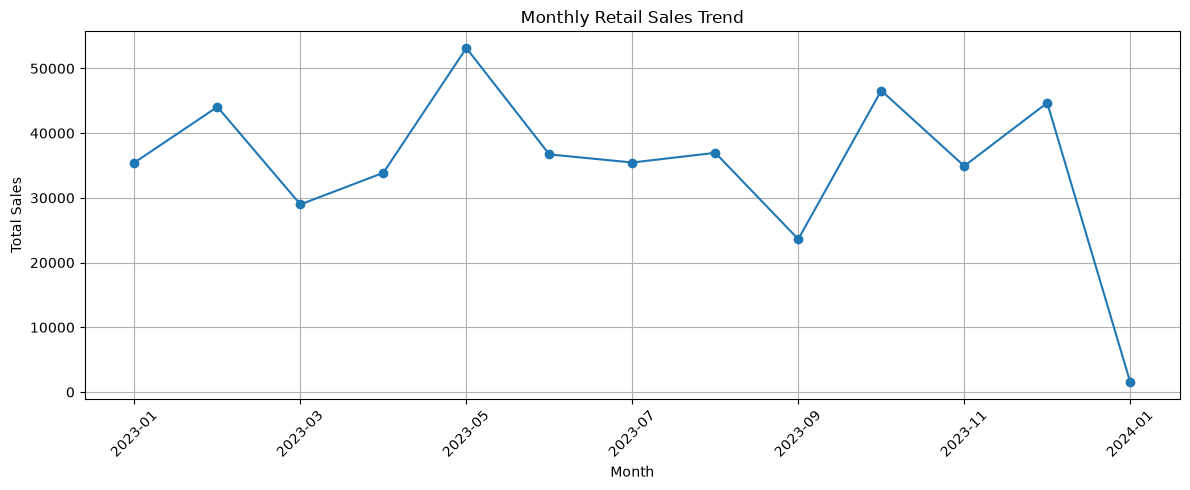

In [12]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation: Monthly Sales Trend

The monthly sales trend shows how total sales revenue changes over time. Months with higher sales indicate stronger sales performance, while months with lower sales may need additional promotions or marketing activities. The business can use this trend to plan inventory and sales campaigns.

In [13]:
category_sales = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

print(category_sales)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


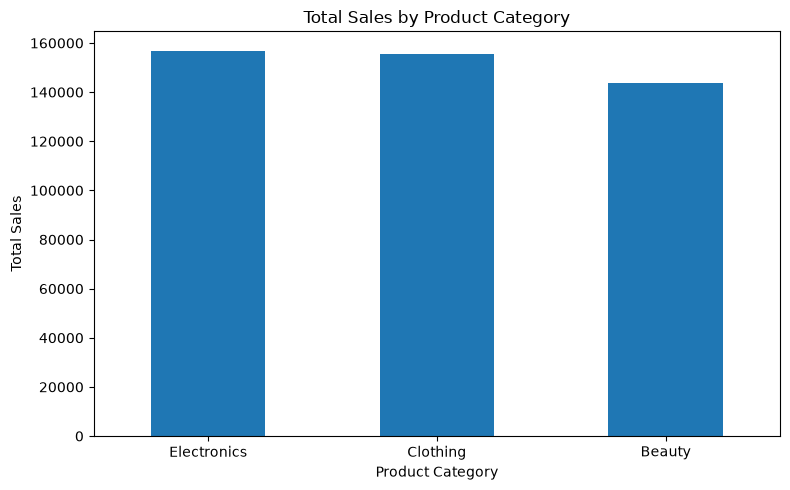

In [14]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Total Sales by Product Category

This bar chart compares the total sales revenue generated by each product category. The category with the highest revenue contributes the most to overall sales, while the category with the lowest revenue may need further analysis and promotional support. The business can use these findings to plan inventory, improve marketing strategies, and focus on customer demand.

In [15]:
print("Highest Revenue Category:", category_sales.idxmax())
print("Highest Category Sales:", category_sales.max())

Highest Revenue Category: Electronics
Highest Category Sales: 156905


In [16]:
gender_sales = df.groupby("Gender")["Total Amount"].sum().sort_values(ascending=False)

print(gender_sales)

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


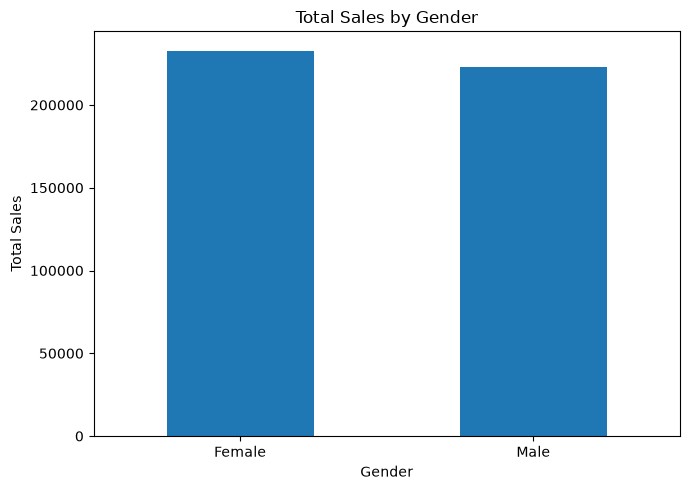

In [17]:
plt.figure(figsize=(7, 5))

gender_sales.plot(kind="bar")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Total Sales by Gender

This chart compares the total sales revenue generated by male and female customers. It helps identify which gender contributes more to overall sales in this dataset. The business can use these insights to understand purchasing patterns and evaluate suitable marketing campaigns for different customer groups.

In [18]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 100],
    labels=["Below 20", "21-30", "31-40", "41-50", "Above 50"],
    include_lowest=True
)

age_sales = df.groupby("Age Group", observed=False)["Total Amount"].sum()

print(age_sales)

Age Group
Below 20     34730
21-30        98215
31-40        95950
41-50        93795
Above 50    133310
Name: Total Amount, dtype: int64


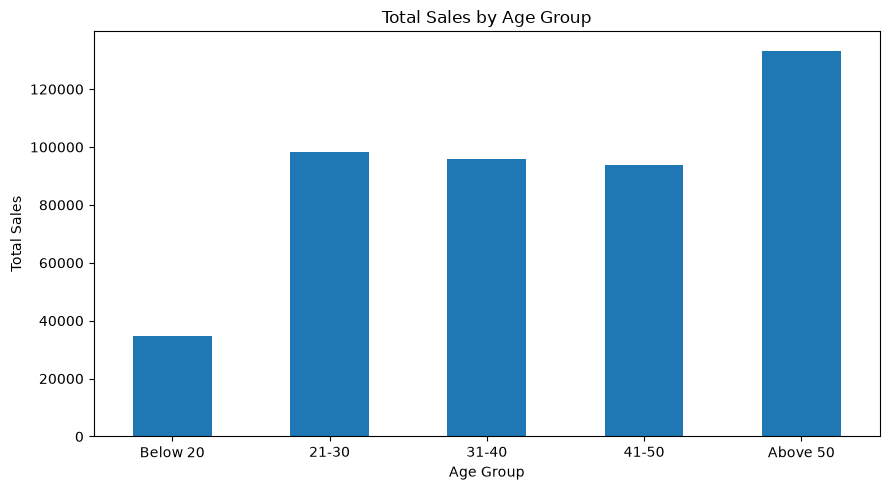

In [19]:
plt.figure(figsize=(9, 5))

age_sales.plot(kind="bar")

plt.title("Total Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Total Sales by Age Group

This chart compares total sales revenue across different customer age groups. It helps identify which age groups contribute more to overall sales. The business can use these insights to understand customer purchasing patterns and develop suitable marketing campaigns and offers for different age groups.

In [20]:
quantity_sales = df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)

print(quantity_sales)

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


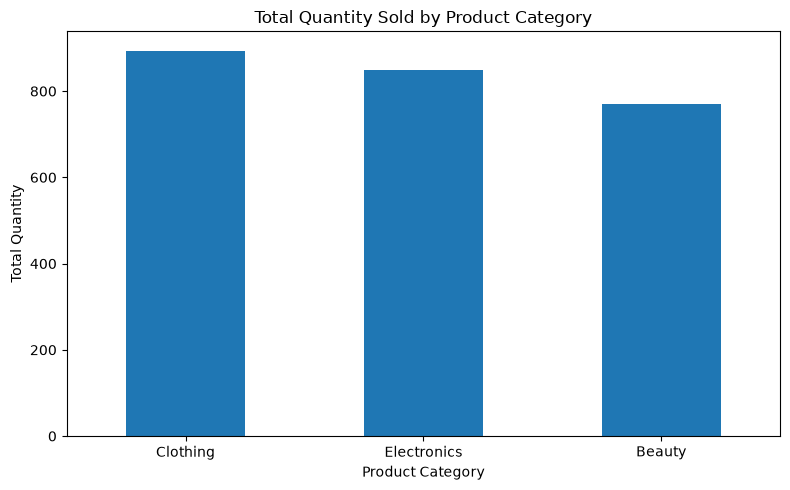

In [21]:
plt.figure(figsize=(8, 5))

quantity_sales.plot(kind="bar")

plt.title("Total Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Total Quantity Sold by Product Category

This chart compares the total number of units sold across different product categories. The category with the highest quantity sold has the greatest sales volume, while categories with lower quantities may need further analysis. The business can use these insights to manage stock levels, forecast demand, and plan suitable promotions for each category.

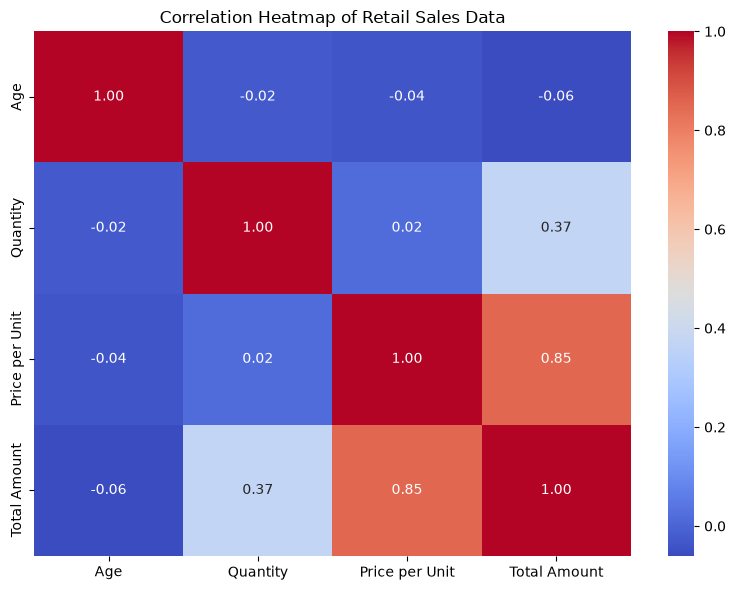

In [22]:
numeric_data = df[["Age", "Quantity", "Price per Unit", "Total Amount"]]

correlation = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

### Observation: Correlation Heatmap of Retail Sales Data

The correlation heatmap illustrates the relationships between numerical variables such as age, quantity, price per unit, and total amount. Positive correlation indicates that two variables tend to increase together, while negative correlation indicates that one tends to decrease as the other increases. These relationships help identify patterns in customer purchases and sales. However, correlation does not necessarily imply causation.

In [23]:
print("Total Transactions:", df["Transaction ID"].nunique())
print("Total Revenue:", df["Total Amount"].sum())
print("Average Transaction Value:", round(df["Total Amount"].mean(), 2))
print("Average Customer Age:", round(df["Age"].mean(), 2))
print("Total Units Sold:", df["Quantity"].sum())

Total Transactions: 1000
Total Revenue: 456000
Average Transaction Value: 456.0
Average Customer Age: 41.39
Total Units Sold: 2514


In [24]:
print("RETAIL SALES EDA - KEY OBSERVATIONS")
print("-" * 40)

print("1. Total Revenue:", df["Total Amount"].sum())

print("2. Average Transaction Value:",
      round(df["Total Amount"].mean(), 2))

print("3. Highest Revenue Category:",
      category_sales.idxmax())

print("4. Highest Revenue Category Sales:",
      category_sales.max())

print("5. Highest Quantity Category:",
      quantity_sales.idxmax())

print("6. Highest Sales Month:",
      monthly_sales.idxmax())

print("7. Total Transactions:",
      df["Transaction ID"].nunique())

print("8. Average Customer Age:",
      round(df["Age"].mean(), 2))

RETAIL SALES EDA - KEY OBSERVATIONS
----------------------------------------
1. Total Revenue: 456000
2. Average Transaction Value: 456.0
3. Highest Revenue Category: Electronics
4. Highest Revenue Category Sales: 156905
5. Highest Quantity Category: Clothing
6. Highest Sales Month: 2023-05
7. Total Transactions: 1000
8. Average Customer Age: 41.39


In [25]:
numeric_cols = df.select_dtypes(include="number")

print("MEAN")
print(numeric_cols.mean())

print("\nMEDIAN")
print(numeric_cols.median())

print("\nMODE")
print(numeric_cols.mode().iloc[0])

print("\nSTANDARD DEVIATION")
print(numeric_cols.std())

MEAN
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE
Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

STANDARD DEVIATION
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


In [26]:
df["Date"] = pd.to_datetime(df["Date"])

quarterly_sales = df.groupby(
    df["Date"].dt.to_period("Q")
)["Total Amount"].sum()

quarterly_sales

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

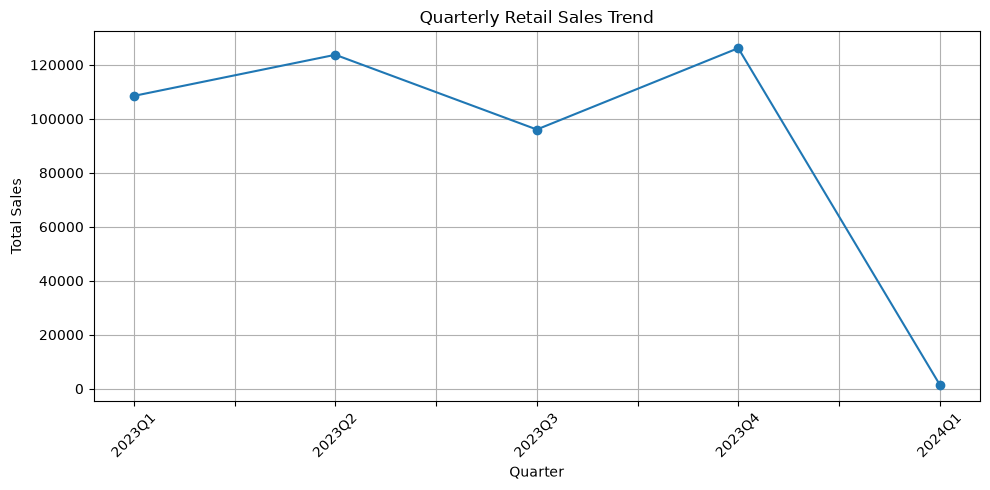

In [27]:
plt.figure(figsize=(10, 5))

quarterly_sales.index = quarterly_sales.index.astype(str)

quarterly_sales.plot(kind="line", marker="o")

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation: Quarterly Sales Trend

The quarterly sales trend compares total revenue across different quarters. It helps identify periods with stronger or weaker sales performance. The business can use this information to plan inventory, staffing, and promotional campaigns according to quarterly demand.

In [28]:
gender_count = df["Gender"].value_counts()

gender_percentage = df["Gender"].value_counts(normalize=True) * 100

print("Gender Count:")
print(gender_count)

print("\nGender Percentage:")
print(gender_percentage.round(2))

Gender Count:
Gender
Female    510
Male      490
Name: count, dtype: int64

Gender Percentage:
Gender
Female    51.0
Male      49.0
Name: proportion, dtype: float64


In [29]:
age_count = df["Age Group"].value_counts().sort_index()

age_percentage = df["Age Group"].value_counts(normalize=True).sort_index() * 100

print("Age Group Count:")
print(age_count)

print("\nAge Group Percentage:")
print(age_percentage.round(2))

Age Group Count:
Age Group
Below 20     63
21-30       210
31-40       193
41-50       221
Above 50    313
Name: count, dtype: int64

Age Group Percentage:
Age Group
Below 20     6.3
21-30       21.0
31-40       19.3
41-50       22.1
Above 50    31.3
Name: proportion, dtype: float64


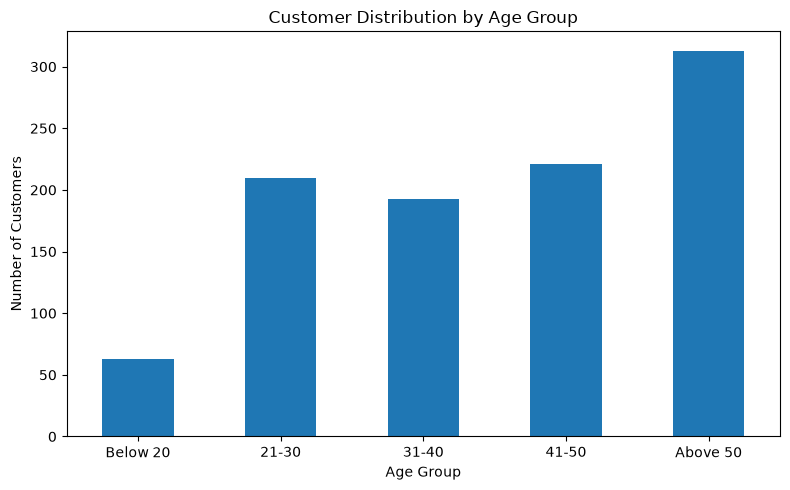

In [30]:
plt.figure(figsize=(8, 5))

age_count.plot(kind="bar")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Customer Distribution by Age Group

This chart shows the distribution of sales transactions across different customer age groups. It helps identify which age groups account for more transactions in the dataset. The business can use these findings to understand its customer demographics and plan suitable marketing campaigns. Since the dataset records transactions, the distribution may not represent the number of unique customers in each age group.

In [31]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Month', 'Age Group']


Average Transaction Value by Gender:
Gender
Female    456.55
Male      455.43
Name: Total Amount, dtype: float64


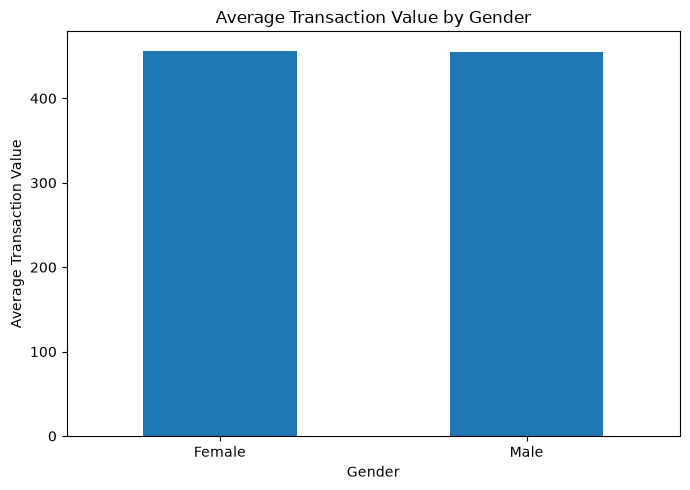

In [32]:
avg_spending_gender = df.groupby("Gender")["Total Amount"].mean()

print("Average Transaction Value by Gender:")
print(avg_spending_gender.round(2))

plt.figure(figsize=(7, 5))
avg_spending_gender.plot(kind="bar")

plt.title("Average Transaction Value by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Transaction Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Average Transaction Value by Gender

This chart compares the average transaction value between male and female customers. The group with the higher average transaction value spends more per transaction on average.

## Conclusion

The retail sales dataset was analysed to understand sales trends, customer demographics, and product category performance. Monthly and quarterly sales trends helped identify changes in revenue over time. Gender-wise and age-group analysis provided insights into customer transaction patterns. The category revenue chart showed which product categories contributed more to total sales. Correlation analysis helped examine relationships between numerical variables.

### Business Recommendations

1. **Improve high-performing categories:** Maintain sufficient stock and promote product categories that generate higher revenue.
2. **Plan seasonal promotions:** Use monthly and quarterly sales trends to plan discounts and marketing campaigns during periods with lower sales.
3. **Target customer segments:** Use gender and age-group transaction patterns to create relevant offers for different customer groups.
4. **Increase average transaction value:** Test product bundles and related-product offers to encourage customers to purchase more per transaction.
5. **Improve future analysis:** Include individual product names and profit information in future datasets to identify best-selling products and the most profitable items.